<a href="https://colab.research.google.com/github/YuYing33/CS521_FA26_HW/blob/main/P1_IBP_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1 — Interval Bound Propagation (IBP) on MNIST

**Architecture:** 784 → 50 → 50 → 50 → 10 (ReLU after each hidden layer).  
**Robustness:** $\ell_\infty$ perturbations, training radius scheduled from 0 to 0.1.  
**Loss:** $\kappa\,CE(z,y)+(1-\kappa)\,CE(\hat z,y)$, $\kappa$ scheduled from 1 to 0.5.

This notebook trains a standard baseline and an IBP model, measures clean and PGD accuracy, compares training time, and computes verified accuracy at 10 radii. Run top-to-bottom in Colab (GPU recommended).

**Important:** the final-layer specification uses class-difference (margin) weights, not independent output-logit intervals.

In [ ]:
import time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

SEED = 0
EPOCHS = 20
BATCH_SIZE = 256
LR = 1e-3
EPS_MAX = 0.1
RAMP_EPOCHS = 15
PGD_STEPS = 40
PGD_RESTARTS = 1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()

transform = transforms.ToTensor()  # pixels in [0,1], consistent with eps=0.1
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
print(len(train_data), len(test_data))

Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 11.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.15MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.82MB/s]

60000 10000


## 1. Model and differentiable bound propagation

For a linear layer $Wx+b$, propagate an input interval $[l,u]$ using its midpoint $m$ and radius $r$:

$ l' = Wm+b-|W|r, \quad u'=Wm+b+|W|r.$

ReLU is monotonic, so apply it to each endpoint. For the **last linear layer**, use $W_y-W_j$ and $b_y-b_j$ to directly bound the true-vs-other-class margins. If $m_j = z_j-z_y$, the worst-case upper bound $\overline m_j$ gives robust pseudo-logits $[0,\overline m_{j\ne y}]$ and robust cross-entropy $\log(1+\sum_{j\ne y}e^{\overline m_j})$. This is equivalent to merging the final layer into the specification.

In [ ]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.ModuleList([nn.Linear(784, 50), nn.Linear(50, 50), nn.Linear(50, 50)])
        self.output = nn.Linear(50, 10)

    def forward(self, x):
        h = x.flatten(1)
        for layer in self.hidden:
            h = F.relu(layer(h))
        return self.output(h)


def linear_interval(lower, upper, layer):
    center, radius = (lower + upper) / 2, (upper - lower) / 2
    out_center = F.linear(center, layer.weight, layer.bias)
    out_radius = F.linear(radius, layer.weight.abs(), None)
    return out_center - out_radius, out_center + out_radius


def margin_upper_bounds(model, x, y, eps):
    """Upper bounds on z_j - z_y for every class j, using difference weights.

    Input domain is intersected with valid pixel range [0,1].
    """
    x = x.flatten(1)
    lower = (x - eps).clamp(0, 1)
    upper = (x + eps).clamp(0, 1)
    for layer in model.hidden:
        lower, upper = linear_interval(lower, upper, layer)
        lower, upper = F.relu(lower), F.relu(upper)

    W, bias = model.output.weight, model.output.bias
    diff_W = W.unsqueeze(0) - W[y].unsqueeze(1)
    diff_b = bias.unsqueeze(0) - bias[y].unsqueeze(1)
    center, radius = (lower + upper) / 2, (upper - lower) / 2
    margin_ub = torch.bmm(diff_W, center.unsqueeze(-1)).squeeze(-1) + diff_b
    margin_ub = margin_ub + torch.bmm(diff_W.abs(), radius.unsqueeze(-1)).squeeze(-1)
    return margin_ub


def robust_ce(model, x, y, eps):
    margins = margin_upper_bounds(model, x, y, eps)
    return F.cross_entropy(margins, y)

m = MNISTMLP().to(DEVICE)
x0, y0 = next(iter(train_loader)); x0, y0 = x0[:8].to(DEVICE), y0[:8].to(DEVICE)
with torch.no_grad():
    margins0 = margin_upper_bounds(m, x0, y0, 0.0)
    logits0 = m(x0)
    true_margins = logits0 - logits0.gather(1, y0[:, None])
    assert torch.allclose(margins0, true_margins, atol=1e-5)
    assert torch.all(margin_upper_bounds(m, x0, y0, 0.1) >= true_margins - 1e-5)
print('IBP sanity checks passed')

IBP sanity checks passed


## 2. Baseline training and IBP training

We use the same model, optimizer, number of epochs, and batch size for both. The IBP schedule is linear in **optimizer steps** over the first `RAMP_EPOCHS`; then it remains at $(\epsilon,\kappa)=(0.1,0.5)$. These are explicit experimental choices; the prompt does not specify epochs or learning rate.

In [ ]:
def schedules(step, steps_per_epoch):
    total_ramp_steps = max(1, RAMP_EPOCHS * steps_per_epoch)
    frac = min(1.0, step / total_ramp_steps)
    return EPS_MAX * frac, 1.0 - 0.5 * frac


def train_model(ibp, seed=SEED):
    seed_all(seed)
    model = MNISTMLP().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    logs = []
    global_step = 0
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        total_loss, total_clean, total_rob, seen = 0., 0., 0., 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            eps, kappa = schedules(global_step, len(train_loader))
            opt.zero_grad(set_to_none=True)
            clean_loss = F.cross_entropy(model(x), y)
            if ibp and kappa < 1.0:
                rob_loss = robust_ce(model, x, y, eps)
                loss = kappa * clean_loss + (1-kappa) * rob_loss
            else:
                rob_loss, loss = clean_loss.detach(), clean_loss
            loss.backward()
            opt.step()
            bs = x.size(0); seen += bs
            total_loss += loss.item() * bs
            total_clean += clean_loss.item() * bs
            total_rob += rob_loss.item() * bs
            global_step += 1
        logs.append(dict(epoch=epoch+1, loss=total_loss/seen,
                         clean_loss=total_clean/seen, robust_loss=total_rob/seen,
                         eps=eps if ibp else 0., kappa=kappa if ibp else 1.))
        print(f'{"IBP" if ibp else "Standard"} epoch {epoch+1:02}/{EPOCHS}: loss={total_loss/seen:.4f}, eps={eps:.3f}, kappa={kappa:.3f}')
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    seconds = time.perf_counter()-start
    return model, pd.DataFrame(logs), seconds

standard_model, standard_history, standard_seconds = train_model(ibp=False)
ibp_model, ibp_history, ibp_seconds = train_model(ibp=True)
print(f'Standard: {standard_seconds:.1f}s; IBP: {ibp_seconds:.1f}s; ratio={ibp_seconds / standard_seconds:.2f}x')
torch.save({'standard': standard_model.state_dict(), 'ibp': ibp_model.state_dict()}, 'p1_models.pt')

Standard epoch 01/20: loss=0.7284, eps=0.007, kappa=0.967
Standard epoch 02/20: loss=0.2758, eps=0.013, kappa=0.933
Standard epoch 03/20: loss=0.2102, eps=0.020, kappa=0.900
Standard epoch 04/20: loss=0.1741, eps=0.027, kappa=0.867
Standard epoch 05/20: loss=0.1463, eps=0.033, kappa=0.833
Standard epoch 06/20: loss=0.1266, eps=0.040, kappa=0.800
Standard epoch 07/20: loss=0.1134, eps=0.047, kappa=0.767
Standard epoch 08/20: loss=0.1020, eps=0.053, kappa=0.733
Standard epoch 09/20: loss=0.0920, eps=0.060, kappa=0.700
Standard epoch 10/20: loss=0.0835, eps=0.067, kappa=0.667
Standard epoch 11/20: loss=0.0765, eps=0.073, kappa=0.633
Standard epoch 12/20: loss=0.0714, eps=0.080, kappa=0.600
Standard epoch 13/20: loss=0.0654, eps=0.087, kappa=0.567
Standard epoch 14/20: loss=0.0594, eps=0.093, kappa=0.533
Standard epoch 15/20: loss=0.0570, eps=0.100, kappa=0.500
Standard epoch 16/20: loss=0.0520, eps=0.100, kappa=0.500
Standard epoch 17/20: loss=0.0493, eps=0.100, kappa=0.500
Standard epoch

## 3. Clean accuracy and PGD robust accuracy

PGD uses the $\ell_\infty$ ball of radius $0.1$, with 40 iterations, random initialization, and projection onto both the perturbation ball and valid pixels. Accuracy is evaluated against the **true label**, not just clean predictions.

In [ ]:
@torch.no_grad()
def clean_accuracy(model, loader=test_loader):
    model.eval(); correct = total = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    return correct / total


def pgd_attack(model, x, y, eps=0.1, steps=40, restarts=1):
    model.eval()
    alpha = max(eps / 10, 0.002)
    lower = (x-eps).clamp(0, 1)
    upper = (x+eps).clamp(0, 1)
    best_adv = x.detach().clone()
    best_loss = torch.full((x.size(0),), -float('inf'), device=x.device)
    for _ in range(restarts):
        adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            adv = adv.detach().requires_grad_(True)
            with torch.enable_grad():
                loss = F.cross_entropy(model(adv), y)
                grad = torch.autograd.grad(loss, adv)[0]
            adv = (adv.detach() + alpha * grad.sign()).maximum(lower).minimum(upper)
        with torch.no_grad():
            per_sample_loss = F.cross_entropy(model(adv), y, reduction='none')
            improved = per_sample_loss > best_loss
            best_loss = torch.where(improved, per_sample_loss, best_loss)
            best_adv[improved] = adv[improved]
    return best_adv.detach()


def pgd_accuracy(model, loader=test_loader, eps=0.1, steps=PGD_STEPS, restarts=PGD_RESTARTS):
    correct = total = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        adv = pgd_attack(model, x, y, eps, steps, restarts)
        with torch.no_grad(): correct += (model(adv).argmax(1) == y).sum().item()
        total += y.numel()
    return correct / total

results_a = pd.DataFrame([
    dict(model='Standard', clean_acc=clean_accuracy(standard_model),
         pgd_acc=pgd_accuracy(standard_model), train_seconds=standard_seconds),
    dict(model='IBP', clean_acc=clean_accuracy(ibp_model),
         pgd_acc=pgd_accuracy(ibp_model), train_seconds=ibp_seconds),
])
results_a['train_minutes'] = results_a.train_seconds / 60
results_a['time_vs_standard'] = results_a.train_seconds / standard_seconds
print(results_a.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
results_a.to_csv('p1_part_a_results.csv', index=False)

   model  clean_acc  pgd_acc  train_seconds  train_minutes  time_vs_standard
Standard      0.973    0.004        148.258          2.471             1.000
     IBP      0.943    0.821        173.215          2.887             1.168


## 4. P1(b): verified accuracy at 10 radii

The box verifier certifies an example iff **every** upper bound on $z_j-z_y$ is strictly negative for $j\ne y$. This also guarantees the center is correctly classified. The same verifier is applied at 0.01, 0.02, ..., 0.10; results must be non-increasing as epsilon grows (up to numerical precision).

This is a direct reimplementation of the HW2-style box verification, using the final-layer margin specification. If your HW2 verifier had a different interface, its equivalent bound check can be substituted here.

 epsilon  verified_accuracy
  0.0100             0.9342
  0.0200             0.9237
  0.0300             0.9122
  0.0400             0.8991
  0.0500             0.8861
  0.0600             0.8693
  0.0700             0.8484
  0.0800             0.8275
  0.0900             0.8012
  0.1000             0.7698


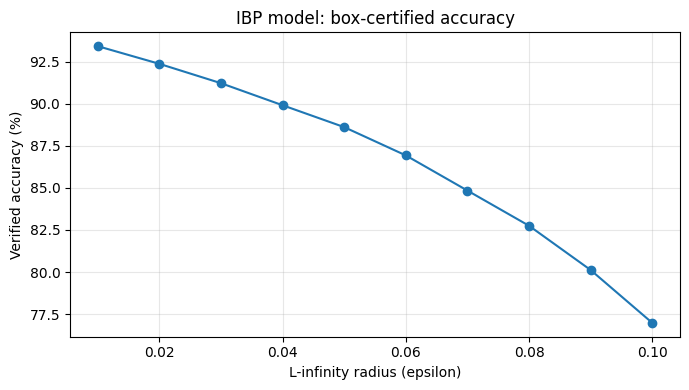

In [ ]:
@torch.no_grad()
def verified_mask(model, x, y, eps):
    margins = margin_upper_bounds(model, x, y, eps)
    margins.scatter_(1, y[:, None], -float('inf'))  # Ignore the zero true-class margin
    return (margins.max(dim=1).values < 0)

@torch.no_grad()
def verified_accuracy(model, loader, eps):
    model.eval(); certified = total = 0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        certified += verified_mask(model,x,y,eps).sum().item()
        total += y.numel()
    return certified/total

epsilons = np.linspace(0.01, 0.1, 10)
certified = [verified_accuracy(ibp_model, test_loader, float(e)) for e in epsilons]
verification_df = pd.DataFrame({'epsilon': epsilons, 'verified_accuracy': certified})
print(verification_df.to_string(index=False, float_format=lambda v:f'{v:.4f}'))
assert np.all(np.diff(certified) <= 1e-6), 'Verify implementation: certification should not improve as radius increases.'
verification_df.to_csv('p1_part_b_verified_accuracy.csv', index=False)
plt.figure(figsize=(7,4)); plt.plot(epsilons, np.array(certified)*100, 'o-')
plt.xlabel('L-infinity radius (epsilon)'); plt.ylabel('Verified accuracy (%)')
plt.title('IBP model: box-certified accuracy'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Adversarial examples among images not certified

**Interpretation caveat:** a failed certificate does **not** prove an adversarial example exists; it can mean that IBP is conservative. We therefore use PGD to search for counterexamples *within each chosen ball*. Show original, adversarial image, and predictions. Images where PGD fails to find a counterexample remain **uncertified**, not necessarily nonrobust.

Inspected 61 uncertified images; PGD found 39 adversarial examples (within inspected subset).


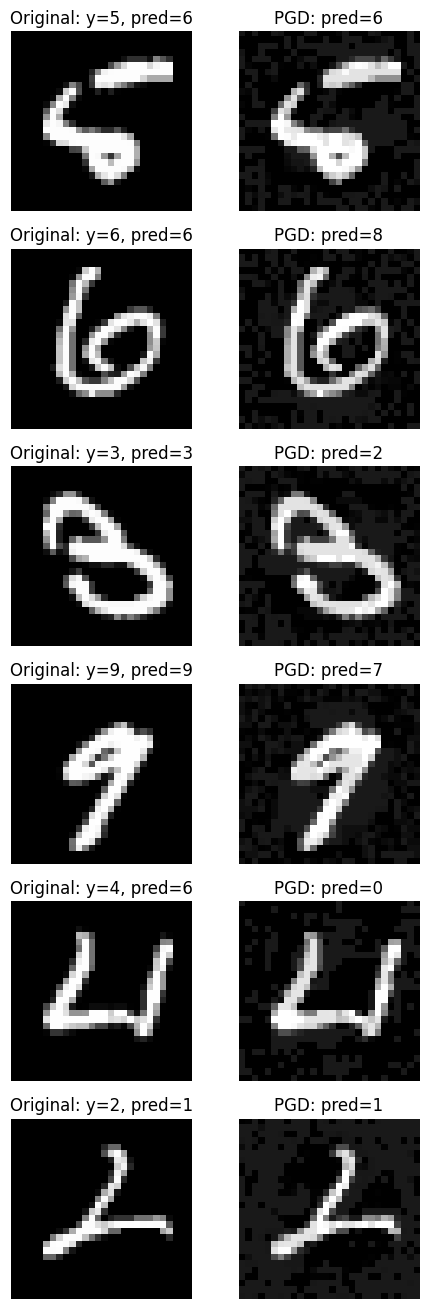

In [ ]:
def collect_examples(model, eps=0.1, max_examples=6):
    model.eval(); examples=[]; uncertified_count=0; found_count=0
    for x,y in test_loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        with torch.no_grad():
            not_cert = ~verified_mask(model,x,y,eps)
        if not not_cert.any(): continue
        cx,cy=x[not_cert],y[not_cert]
        uncertified_count += len(cy)
        adversarial = pgd_attack(model,cx,cy,eps=eps,steps=PGD_STEPS,restarts=PGD_RESTARTS)
        with torch.no_grad():
            clean_pred = model(cx).argmax(1)
            adv_pred = model(adversarial).argmax(1)
            success=(adv_pred!=cy)
        found_count += success.sum().item()
        for i in torch.where(success)[0].tolist():
            if len(examples)<max_examples:
                examples.append((cx[i].cpu(),adversarial[i].cpu(),int(cy[i]),int(clean_pred[i]),int(adv_pred[i])))
        if len(examples)>=max_examples: break
    return examples, uncertified_count, found_count

examples, inspected, found = collect_examples(ibp_model, eps=0.1)
print(f'Inspected {inspected} uncertified images; PGD found {found} adversarial examples (within inspected subset).')
if examples:
    fig, axes=plt.subplots(len(examples), 2, figsize=(5,2.2*len(examples)), squeeze=False)
    for row,(original,adv,label,clean_pred,adv_pred) in enumerate(examples):
        axes[row,0].imshow(original.squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[row,0].set_title(f'Original: y={label}, pred={clean_pred}')
        axes[row,1].imshow(adv.squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[row,1].set_title(f'PGD: pred={adv_pred}')
        for ax in axes[row]: ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('No PGD counterexamples found among the inspected uncertified samples.')